In [1]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from lmfit.models import GaussianModel, VoigtModel, ConstantModel
from scipy.special import wofz
from scipy.signal import find_peaks
from scipy.ndimage import median_filter
from scipy.interpolate import UnivariateSpline
from pathlib import Path

<h2 style="color: #e19edc;"> Antares</h2>

<h3 style="color: #e19edc;"> Espectros que viene con longitud de onda y flujo</h3>
<h3 style="color: #e19edc;"> 2023</h3>

In [2]:
ruta_24_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\agosto 24 de 2023.xlsx"
ruta_29_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\agosto 29 de 2023.xlsx"
ruta_01_septiembre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\septiembre 1 de 2023.xlsx"
ruta_08_septiembre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\septiembre 8 de 2023.xlsx"
ruta_12_octubre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\octubre 12 de 2023.xlsx"
ruta_19_octubre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\octubre 19 de 2023.xlsx"

In [3]:
antares_24_agosto = pd.read_excel(ruta_24_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_29_agosto = pd.read_excel(ruta_29_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_01_septiembre = pd.read_excel(ruta_01_septiembre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_08_septiembre = pd.read_excel(ruta_08_septiembre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_12_octubre = pd.read_excel(ruta_12_octubre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_19_octubre = pd.read_excel(ruta_19_octubre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])

<h4 style="color: #e19edc;"> Parámetros de la normalización con el método Sigma - Clipping</h4>
<h5 style="color: #e19edc;"> Normalización de espectros</h5>

In [6]:
espectros_por_normalizar = {
    "antares_24_agosto": antares_24_agosto,
    "antares_29_agosto": antares_29_agosto,
    "antares_01_septiembre": antares_01_septiembre,
    "antares_08_septiembre": antares_08_septiembre,
    "antares_12_octubre": antares_12_octubre,
    "antares_19_octubre": antares_19_octubre,
}

In [ ]:
guardar_graficos = True   
carpeta_graficos = "./Graficas 2023/Espectros_normalizados"  
 
col_longitud_onda = "Longitud onda"
col_flujo = "Flujo"
 
grado_polinomio= 2     
N_iteraciones = 10
sigma_corte = 2.0

In [7]:
def ajustar_continuo(longitud_onda, flujo, grado, n_iter, sigma):

    longitud_onda = np.asarray(longitud_onda, dtype=float)
    flujo = np.asarray(flujo, dtype=float)
 
    mascara = np.ones_like(flujo, dtype=bool)
 
    for _ in range(n_iter):
        coef = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
        continuo_iter = np.polyval(coef, longitud_onda)
 
        residuo = flujo - continuo_iter
        
        mediana = np.median(residuo[mascara])
        mad = np.median(np.abs(residuo[mascara] - mediana))
        mad_std = mad * 1.4826

        umbral_superior = mediana + sigma * mad_std
        umbral_inferior = mediana - sigma * mad_std
        nueva_mascara = (residuo > umbral_inferior) & (residuo < umbral_superior)
 
        if nueva_mascara.sum() < grado + 2:
            break

        if np.array_equal(nueva_mascara, mascara):
            break
 
        mascara = nueva_mascara
 
    coef_final = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
    continuo = np.polyval(coef_final, longitud_onda)
 
    return continuo, mascara


Procesando: antares_24_agosto
  Puntos totales: 180
  Puntos excluidos: 44
  -> Gráfico guardado: Graficas 2023, 2024, 2025 y 2026\Espectros_normalizados\antares_24_agosto_control.png


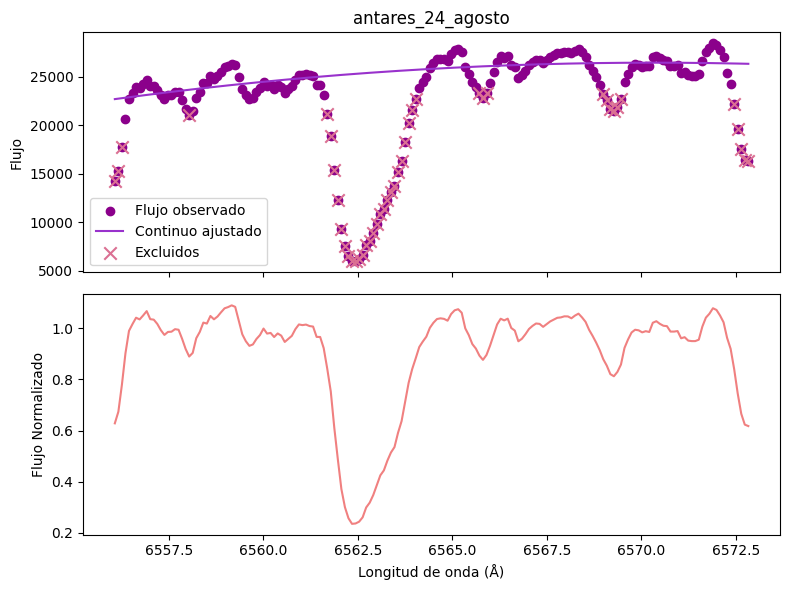


Procesando: antares_29_agosto
  Puntos totales: 180
  Puntos excluidos: 55
  -> Gráfico guardado: Graficas 2023, 2024, 2025 y 2026\Espectros_normalizados\antares_29_agosto_control.png


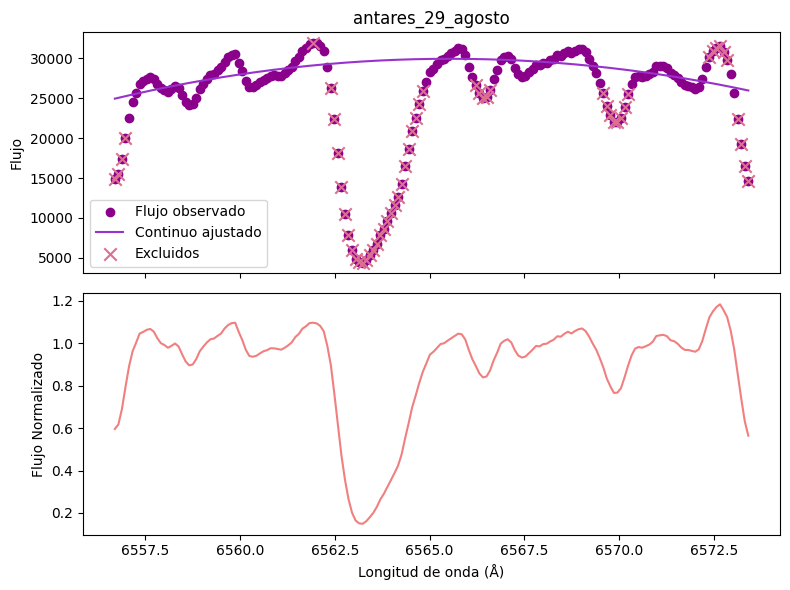


Procesando: antares_01_septiembre
  Puntos totales: 180
  Puntos excluidos: 58
  -> Gráfico guardado: Graficas 2023, 2024, 2025 y 2026\Espectros_normalizados\antares_01_septiembre_control.png


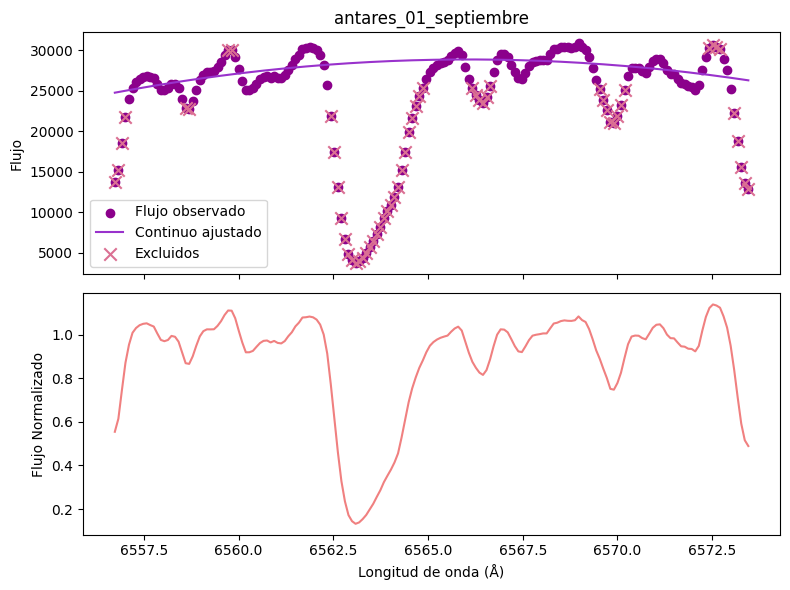


Procesando: antares_08_septiembre
  Puntos totales: 180
  Puntos excluidos: 53
  -> Gráfico guardado: Graficas 2023, 2024, 2025 y 2026\Espectros_normalizados\antares_08_septiembre_control.png


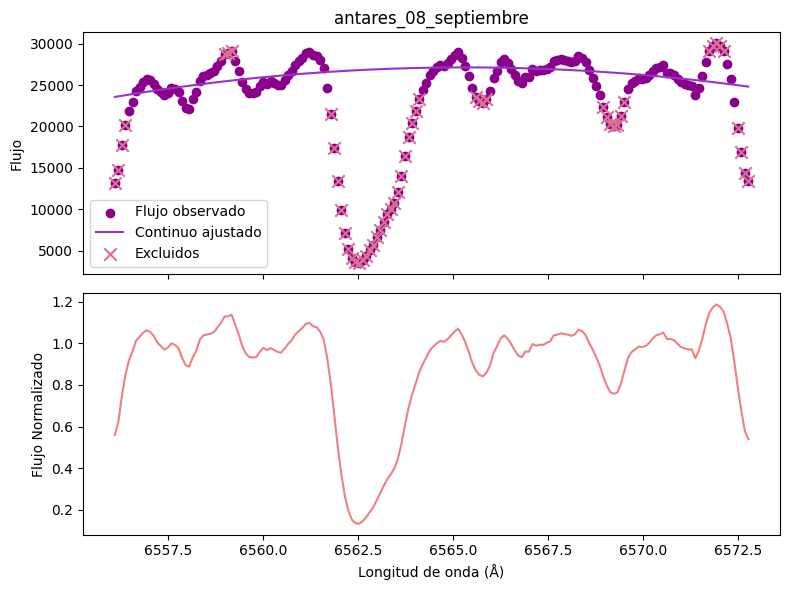


Procesando: antares_12_octubre
  Puntos totales: 180
  Puntos excluidos: 72
  -> Gráfico guardado: Graficas 2023, 2024, 2025 y 2026\Espectros_normalizados\antares_12_octubre_control.png


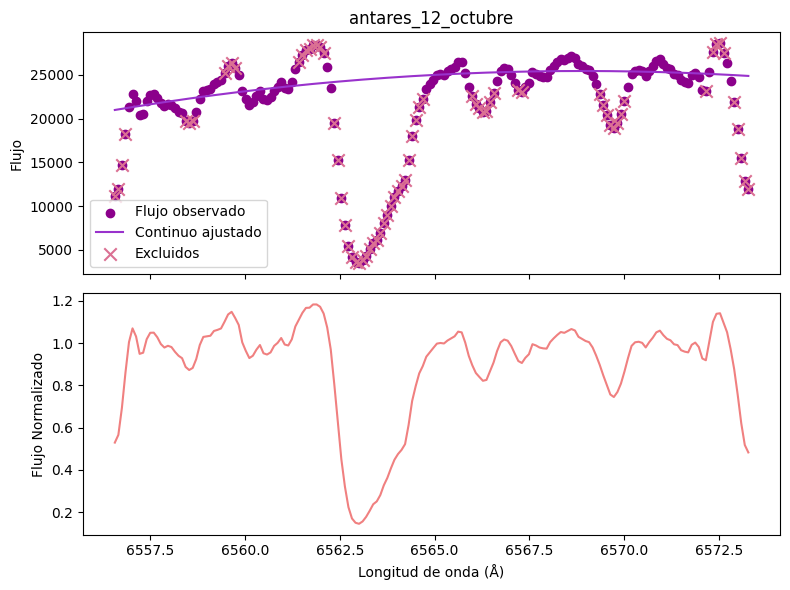


Procesando: antares_19_octubre
  Puntos totales: 180
  Puntos excluidos: 88
  -> Gráfico guardado: Graficas 2023, 2024, 2025 y 2026\Espectros_normalizados\antares_19_octubre_control.png


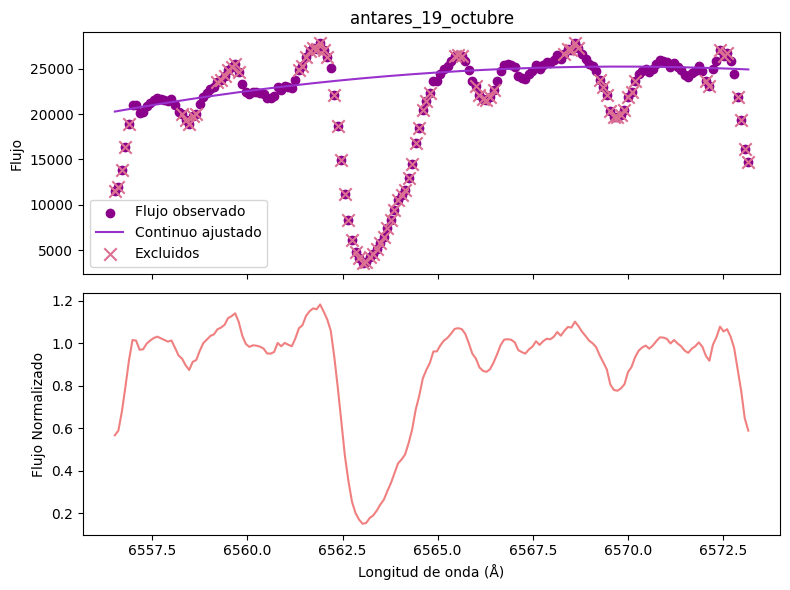


Proceso completo.


In [9]:
if guardar_graficos:
    Path(carpeta_graficos).mkdir(exist_ok=True)
 
for nombre, df in espectros_por_normalizar.items():
    print(f"\nProcesando: {nombre}")
 
    longitud_onda = df[col_longitud_onda].values
    flujo = df[col_flujo].values
 
    continuo, mascara_continuo = ajustar_continuo(longitud_onda, flujo, grado_polinomio, N_iteraciones, sigma_corte)

    df["Continuo ajustado"] = continuo
    df["Flujo Normalizado"] = flujo / continuo
    df["Usado en ajuste"] = mascara_continuo

    print(f"  Puntos totales: {len(mascara_continuo)}")
    print(f"  Puntos excluidos: {(~mascara_continuo).sum()}")

    mascara_bool = np.asarray(mascara_continuo, dtype=bool)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
 
    ax1.scatter(longitud_onda, flujo, color = "darkmagenta", label="Flujo observado")
    ax1.plot(longitud_onda, continuo, color ="darkorchid", label="Continuo ajustado")
    ax1.scatter(longitud_onda[~mascara_bool], flujo[~mascara_bool], color = "palevioletred",marker = "x", label="Excluidos", s = 80)
    ax1.set_ylabel("Flujo")
    ax1.legend()
    ax1.set_title(nombre)
 
    ax2.plot(longitud_onda, df["Flujo Normalizado"], color ="lightcoral")
    ax2.set_ylabel("Flujo Normalizado")
    ax2.set_xlabel("Longitud de onda (Å)")
 
    plt.tight_layout()
 
    if guardar_graficos:
        fig_path = Path(carpeta_graficos) / f"{nombre}_control.png"
        plt.savefig(fig_path, dpi=120)
        print(f"  -> Gráfico guardado: {fig_path}")
 
    plt.show()
    plt.close(fig)
 
print("\nProceso completo.")

<h3 style="color: #e19edc;"> Obtención del perfil de absorción y emisión de la línea H<sub>&alpha;</sub></h3>
<h4 style="color: #e19edc;"> Teniendo en cuenta las posibles mezclas con las líneas de absorción</h4>
<h5 style="color: #e19edc;"> Datos </h5>

In [10]:
# Datos completos
archivos = [
    {
        "fecha": "Septiembre 11-2023",
        "datos": antares_01_septiembre,
        "ventana_vecinos":4,
        "centro_aprox": 6563.185,
        "velocidad_metalica": 19.4,  # km/s
        "incertidumbre_v": 0.36,
        "velocidad_telurica": -18.65, #km/s
    },
]